# EDA Hubs – Método 2 (KMedoids / Clustering)
Análisis exploratorio de los hubs del método 2 y sus cargas asignadas.
- **Hubs**: `final_results.csv`
- **Cargas asignadas**: `hubs_assign_m2.parquet` (generado en notebook 1)

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import plotly.express as px
import folium
from folium.plugins import HeatMap
import ast
import warnings
warnings.filterwarnings('ignore')

region5 = {
    'AL': 'SOUTHEAST', 'AR': 'SOUTHEAST', 'GA': 'SOUTHEAST', 'MS': 'SOUTHEAST',
    'VA': 'SOUTHEAST', 'KY': 'SOUTHEAST', 'TN': 'SOUTHEAST', 'FL': 'SOUTHEAST',
    'SC': 'SOUTHEAST', 'NC': 'SOUTHEAST', 'WV': 'SOUTHEAST', 'LA': 'SOUTHEAST',
    'AZ': 'SOUTHWEST', 'NM': 'SOUTHWEST', 'TX': 'SOUTHWEST', 'OK': 'SOUTHWEST',
    'IL': 'MIDWEST', 'IA': 'MIDWEST', 'NE': 'MIDWEST', 'SD': 'MIDWEST',
    'MO': 'MIDWEST', 'IN': 'MIDWEST', 'MN': 'MIDWEST', 'MI': 'MIDWEST',
    'WI': 'MIDWEST', 'KS': 'MIDWEST', 'ND': 'MIDWEST', 'OH': 'MIDWEST',
    'UT': 'WEST', 'NV': 'WEST', 'ID': 'WEST', 'WY': 'WEST',
    'CO': 'WEST', 'MT': 'WEST', 'WA': 'WEST', 'OR': 'WEST', 'CA': 'WEST',
    'MD': 'NORTHEAST', 'ME': 'NORTHEAST', 'NH': 'NORTHEAST', 'VT': 'NORTHEAST',
    'MA': 'NORTHEAST', 'PA': 'NORTHEAST', 'NY': 'NORTHEAST', 'RI': 'NORTHEAST',
    'CT': 'NORTHEAST', 'NJ': 'NORTHEAST', 'DE': 'NORTHEAST'
}

In [2]:
import numpy as np

def haversine_vec(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 3958.8 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

## 1. Cargar datos

In [3]:
import gc

COLS = [
    'ID', 'near_hub_m2', 'near_hub_name_m2', 'near_hub_dest_m2', 'near_hub_name_dest_m2',
    'tier_hub_m2', 'hubs_50m_m2',
    'LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination',
    'StateOrigin', 'StateDestination', 'RatePerMile', 'Distance'
]

_probe = pl.read_parquet('hubs_assign_m2.parquet', n_rows=1)
real_cols = [c for c in COLS if c in _probe.columns]

df = (
    pl.scan_parquet('hubs_assign_m2.parquet')
    .select(real_cols)
    .collect()
    .to_pandas()
)

for col in ['LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination']:
    if col in df.columns:
        df[col] = df[col].astype('float32')

print(f'Total cargas: {df.shape[0]:,} | Memoria: {df.memory_usage(deep=True).sum()/1e6:.0f} MB')
df.head()

Total cargas: 57,573,489 | Memoria: 15341 MB


,ID,near_hub_m2,near_hub_name_m2,near_hub_dest_m2,near_hub_name_dest_m2,tier_hub_m2,hubs_50m_m2,LatOrigin,LngOrigin,LatDestination,LngDestination,StateOrigin,StateDestination,RatePerMile,Distance
0,0.0,C2,Cluster_2,86.0,Pico CA,terciario,[],43.180199,-124.184097,37.526501,-121.985199,OR,CA,NaN,530.0
1,1.0,11.0,Pico CA,136.0,Pico OR,primaria,[],34.527699,-117.353600,45.147301,-122.860298,CA,OR,NaN,973.0
2,2.0,C16,Cluster_16,C9,Cluster_9,terciario,[C16],37.976501,-121.310898,44.056198,-121.308701,CA,OR,NaN,483.0
3,3.0,C16,Cluster_16,C8,Cluster_8,terciario,[],39.081699,-121.554901,45.832298,-119.285797,CA,OR,NaN,613.0
4,4.0,11.0,Pico CA,C2,Cluster_2,primaria,[],33.924400,-117.204498,44.627399,-123.096603,CA,OR,NaN,958.0


In [4]:
hubs_m2_raw = pd.read_csv('../5. merge dbscan/results/final_results.csv')
primaria   = hubs_m2_raw[hubs_m2_raw['Z'] == 1.0].copy()
secundaria = hubs_m2_raw[(hubs_m2_raw['Z'] < 1.0) & (hubs_m2_raw['new_name'].notna())].copy()
terciario  = hubs_m2_raw[hubs_m2_raw['new_name'].isna()].copy()

rows = []
for _, r in primaria.iterrows():
    rows.append({'hub_id': str(r['id']), 'hub_name': r['new_name'],
                 'lat': r['lat'], 'lng': r['lng'], 'tier': 'primaria'})
for _, r in secundaria.iterrows():
    rows.append({'hub_id': str(r['id']), 'hub_name': r['new_name'],
                 'lat': r['lat'], 'lng': r['lng'], 'tier': 'secundaria'})
for _, r in terciario.iterrows():
    cid = str(int(r['cluster'])) if pd.notna(r.get('cluster')) else str(_)
    rows.append({'hub_id': f'C{cid}', 'hub_name': f'Cluster_{cid}',
                 'lat': r['lat'], 'lng': r['lng'], 'tier': 'terciario'})

hubs_table = pd.DataFrame(rows).dropna(subset=['lat', 'lng']).reset_index(drop=True)
print(f'hubs_table: {len(hubs_table)} hubs ({hubs_table["tier"].value_counts().to_dict()})')

hubs_table: 192 hubs ({'terciario': 104, 'primaria': 47, 'secundaria': 41})


## 2. Distribución de cargas por hub M2

In [5]:
cargas_orig = df.groupby('near_hub_m2')['ID'].count().rename('cargas_origen').reset_index().rename(columns={'near_hub_m2': 'hub_id'})
cargas_dest = df.groupby('near_hub_dest_m2')['ID'].count().rename('cargas_dest').reset_index().rename(columns={'near_hub_dest_m2': 'hub_id'})

hub_stats = (
    hubs_table
    .merge(cargas_orig, on='hub_id', how='left')
    .merge(cargas_dest, on='hub_id', how='left')
)
hub_stats['cargas_origen'] = hub_stats['cargas_origen'].fillna(0).astype(int)
hub_stats['cargas_dest']   = hub_stats['cargas_dest'].fillna(0).astype(int)
hub_stats['total_cargas']  = hub_stats['cargas_origen'] + hub_stats['cargas_dest']
hub_stats['inbound_ratio'] = hub_stats['cargas_dest'] / (hub_stats['total_cargas'] + 1e-9)

hub_stats.sort_values('total_cargas', ascending=False).head(10)

,hub_id,hub_name,lat,lng,tier,cargas_origen,cargas_dest,total_cargas,inbound_ratio
11,42.0,Pico IL,41.893900,-87.951229,primaria,2267607,1893957,4161564,0.455107
118,C14,Cluster_14,40.760294,-87.081044,terciario,2133984,2010542,4144526,0.485108
141,C14,Cluster_14,36.118691,-78.727584,terciario,2133984,2010542,4144526,0.485108
129,C14,Cluster_14,38.178340,-92.643660,terciario,2133984,2010542,4144526,0.485108
165,C14,Cluster_14,34.403702,-79.417098,terciario,2133984,2010542,4144526,0.485108
173,C14,Cluster_14,25.946822,-97.447415,terciario,2133984,2010542,4144526,0.485108
102,C14,Cluster_14,38.116614,-105.404396,terciario,2133984,2010542,4144526,0.485108
97,C14,Cluster_14,32.731673,-115.530728,terciario,2133984,2010542,4144526,0.485108
39,183.0,Pico TX,32.853836,-96.990061,primaria,1922585,2092145,4014730,0.521117
8,36.0,Pico GA,33.697806,-84.482410,primaria,1526120,1958210,3484330,0.562005


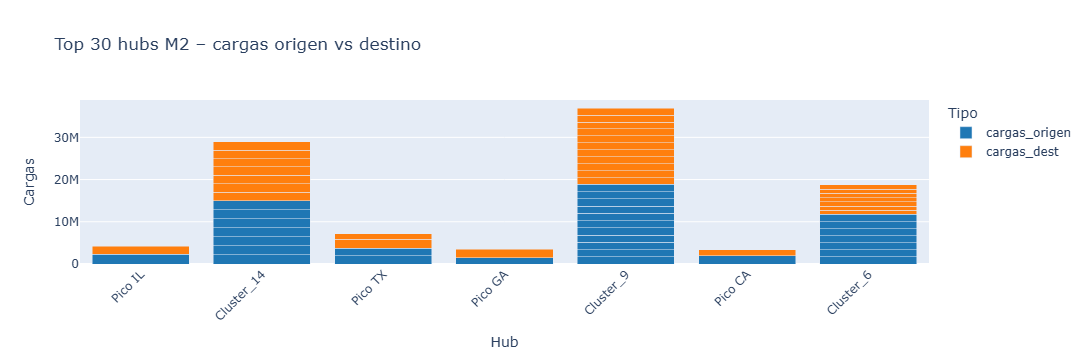

In [6]:
top30 = hub_stats.sort_values('total_cargas', ascending=False).head(30)
fig = px.bar(
    top30, x='hub_name', y=['cargas_origen', 'cargas_dest'],
    color_discrete_map={'cargas_origen': '#1f77b4', 'cargas_dest': '#ff7f0e'},
    title='Top 30 hubs M2 – cargas origen vs destino',
    labels={'value': 'Cargas', 'variable': 'Tipo', 'hub_name': 'Hub'},
    barmode='stack'
)
fig.update_layout(xaxis_tickangle=-45)
fig.show()

## 3. Mapa de hubs con radio 50 millas

In [7]:
tier_colors = {'primaria': 'red', 'secundaria': 'orange', 'terciario': 'blue'}
m = folium.Map(location=[38.5, -96], zoom_start=4, tiles='OpenStreetMap')
max_loads = hub_stats['total_cargas'].max() or 1

for _, row in hub_stats.iterrows():
    color = tier_colors.get(row['tier'], 'gray')
    pct   = row['total_cargas'] / max_loads
    folium.Circle(
        location=[row['lat'], row['lng']],
        radius=80467,
        color=color, fill=False, weight=1, opacity=0.4
    ).add_to(m)
    folium.CircleMarker(
        location=[row['lat'], row['lng']],
        radius=max(4, int(10 * pct)),
        color=color, fill=True, fill_opacity=0.7,
        popup=folium.Popup(
            f"<b>{row['hub_name']}</b> [{row['tier']}]<br>"
            f"Origen: {row['cargas_origen']:,}<br>Destino: {row['cargas_dest']:,}",
            max_width=200
        )
    ).add_to(m)

legend_html = '''
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;
            background:white;padding:10px;border:2px solid gray;font-size:12px">
<b>Tier</b><br>
<span style="color:red">●</span> Primaria<br>
<span style="color:orange">●</span> Secundaria<br>
<span style="color:blue">●</span> Terciario
</div>'''
m.get_root().html.add_child(folium.Element(legend_html))
m.save('map_m2_hubs_50mi.html')
print('✓ Mapa guardado: map_m2_hubs_50mi.html')

✓ Mapa guardado: map_m2_hubs_50mi.html


## 4. Cobertura por estado

Cobertura global origen M2: 99.1%
Cobertura global destino M2: 99.1%


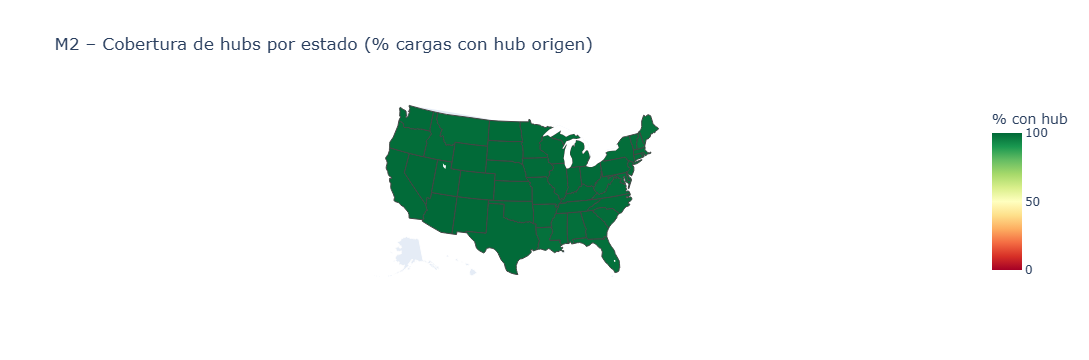

In [8]:
df['tiene_hub_m2']      = df['near_hub_m2'].notna()
df['tiene_hub_dest_m2'] = df['near_hub_dest_m2'].notna()

cobertura_estado = (
    df.groupby('StateOrigin')
    .agg(total=('ID', 'count'), con_hub=('tiene_hub_m2', 'sum'))
    .assign(pct_cobertura=lambda x: 100 * x['con_hub'] / x['total'])
    .reset_index()
)

print(f'Cobertura global origen M2: {100 * df["tiene_hub_m2"].mean():.1f}%')
print(f'Cobertura global destino M2: {100 * df["tiene_hub_dest_m2"].mean():.1f}%')

fig_cob = px.choropleth(
    cobertura_estado,
    locations='StateOrigin', locationmode='USA-states',
    color='pct_cobertura', scope='usa',
    color_continuous_scale='RdYlGn', range_color=[0, 100],
    title='M2 – Cobertura de hubs por estado (% cargas con hub origen)',
    labels={'pct_cobertura': '% con hub', 'StateOrigin': 'Estado'}
)
fig_cob.show()

## 5. Cobertura dentro de radio 50 millas

In [ ]:
if 'hubs_50m_m2' in df.columns:
    def _parse_hub_list(x):
        if isinstance(x, list):   # primero: lista nativa
            return len(x)
        if x is None:
            return 0
        try:
            if pd.isna(x):
                return 0
        except Exception:
            pass
        s = str(x).strip()
        if s in ('', '[]', 'nan'):
            return 0
        try:
            return len(ast.literal_eval(s))
        except Exception:
            return int(bool(s))

    df['en_radio_50'] = df['hubs_50m_m2'].apply(_parse_hub_list) > 0
    print(f'Cargas con al menos 1 hub M2 en 50 millas: {100 * df["en_radio_50"].mean():.1f}%')

    cob_50_estado = (
        df.groupby('StateOrigin')
        .agg(total=('ID', 'count'), en_radio=('en_radio_50', 'sum'))
        .assign(pct=lambda x: 100 * x['en_radio'] / x['total'])
        .reset_index()
    )
    fig_50 = px.choropleth(
        cob_50_estado,
        locations='StateOrigin', locationmode='USA-states',
        color='pct', scope='usa',
        color_continuous_scale='Blues', range_color=[0, 100],
        title='M2 – % cargas con hub dentro de 50 millas',
        labels={'pct': '% en radio 50mi', 'StateOrigin': 'Estado'}
    )
    fig_50.show()

## 6. Ratio inbound/outbound por estado

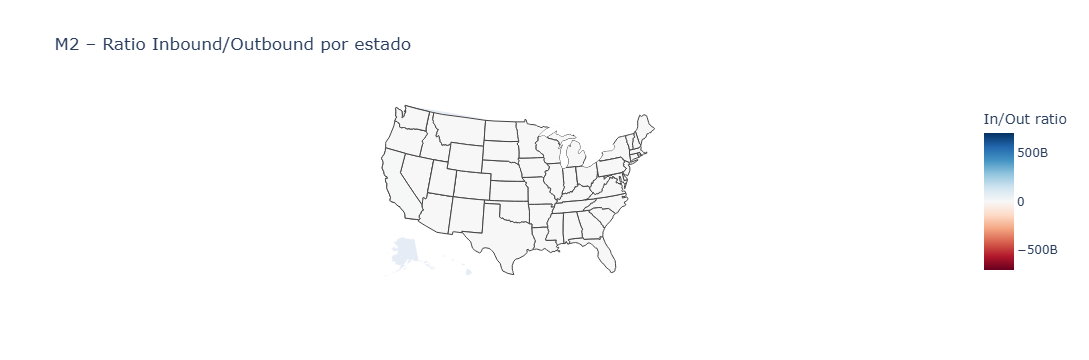

In [11]:
outbound = df.groupby('StateOrigin')['ID'].count().rename('outbound')
inbound  = df.groupby('StateDestination')['ID'].count().rename('inbound')
io_ratio = pd.concat([outbound, inbound], axis=1).fillna(0).reset_index()
io_ratio.columns = ['state', 'outbound', 'inbound']
io_ratio['ratio'] = io_ratio['inbound'] / (io_ratio['outbound'] + 1e-9)

fig_io = px.choropleth(
    io_ratio,
    locations='state', locationmode='USA-states',
    color='ratio', scope='usa',
    color_continuous_scale='RdBu', color_continuous_midpoint=1.0,
    title='M2 – Ratio Inbound/Outbound por estado',
    labels={'ratio': 'In/Out ratio', 'state': 'Estado'}
)
fig_io.show()

## 7. Análisis por región

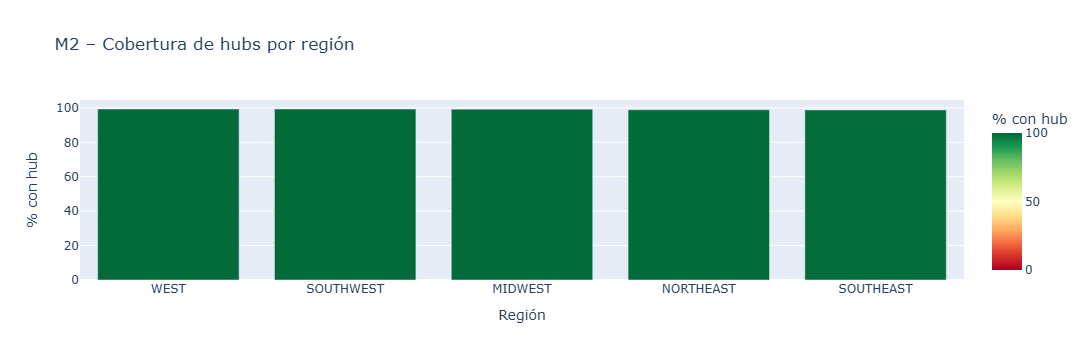

In [12]:
df['region_origen'] = df['StateOrigin'].map(region5)
region_stats = (
    df.groupby('region_origen')
    .agg(total=('ID', 'count'), con_hub=('tiene_hub_m2', 'sum'))
    .assign(pct_cobertura=lambda x: 100 * x['con_hub'] / x['total'])
    .reset_index()
    .sort_values('pct_cobertura', ascending=False)
)
fig_reg = px.bar(
    region_stats, x='region_origen', y='pct_cobertura',
    color='pct_cobertura', color_continuous_scale='RdYlGn', range_color=[0, 100],
    title='M2 – Cobertura de hubs por región',
    labels={'pct_cobertura': '% con hub', 'region_origen': 'Región'}
)
fig_reg.show()

In [13]:
sample = df[['LatOrigin', 'LngOrigin']].dropna().sample(min(20_000, len(df)), random_state=42)
m_heat = folium.Map(
    location=[38.5, -96], zoom_start=4,
    tiles='https://tiles.stadiamaps.com/tiles/alidade_smooth_dark/{z}/{x}/{y}{r}.png',
    attr='© Stadia Maps © OpenMapTiles © OpenStreetMap contributors'
)
HeatMap(sample.values.tolist(), radius=8, blur=10, min_opacity=0.3).add_to(m_heat)
m_heat.save('map_m2_heatmap.html')
print('✓ Mapa guardado: map_m2_heatmap.html')

✓ Mapa guardado: map_m2_heatmap.html


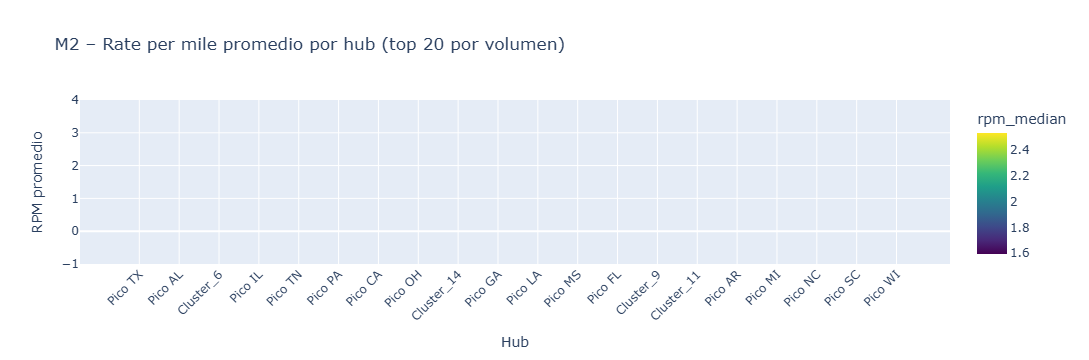

In [14]:
if 'RatePerMile' in df.columns and 'near_hub_name_m2' in df.columns:
    rpm_hub = (
        df[df['near_hub_name_m2'].notna()]
        .groupby('near_hub_name_m2')['RatePerMile']
        .agg(['mean', 'median', 'count'])
        .reset_index()
        .rename(columns={'mean': 'rpm_mean', 'median': 'rpm_median',
                         'count': 'n_cargas', 'near_hub_name_m2': 'hub'})
        .sort_values('n_cargas', ascending=False)
        .head(20)
    )
    fig_rpm = px.scatter(
        rpm_hub, x='hub', y='rpm_mean',
        size='n_cargas', color='rpm_median',
        color_continuous_scale='Viridis',
        title='M2 – Rate per mile promedio por hub (top 20 por volumen)',
        labels={'rpm_mean': 'RPM promedio', 'hub': 'Hub', 'n_cargas': 'N cargas'}
    )
    fig_rpm.update_layout(xaxis_tickangle=-45)
    fig_rpm.show()

## 10. Cargas por tier

In [ ]:
if 'tier_hub_m2' in df.columns:
    tier_counts = df['tier_hub_m2'].value_counts().reset_index()
    tier_counts.columns = ['tier', 'cargas']
    fig_tier = px.pie(
        tier_counts, names='tier', values='cargas',
        title='M2 – Distribución de cargas por tier del hub asignado',
        color='tier',
        color_discrete_map={'primaria': '#d62728', 'secundaria': '#ff7f0e', 'terciario': '#1f77b4'}
    )
    fig_tier.show()
else:
    print('Columna tier_hub_m2 no disponible en este parquet.')

## 11. Deadhead por hub M2 (distancia carga → hub asignado)

In [ ]:
hub_coords_m2 = (
    hubs_table[['hub_id', 'lat', 'lng']]
    .drop_duplicates(subset=['hub_id'])  # evita producto cartesiano en el merge
    .rename(columns={'lat': 'hub_lat', 'lng': 'hub_lng'})
)
df_dh = (
    df[df['near_hub_m2'].notna() & df['LatOrigin'].notna()]
    .merge(hub_coords_m2, left_on='near_hub_m2', right_on='hub_id', how='left')
)

# Haversine vectorizado
df_dh['deadhead_mi'] = haversine_vec(
    df_dh['LatOrigin'].values, df_dh['LngOrigin'].values,
    df_dh['hub_lat'].values,   df_dh['hub_lng'].values
)

print(f'Deadhead promedio global M2: {df_dh["deadhead_mi"].mean():.1f} millas')
print(f'Deadhead mediano global M2:  {df_dh["deadhead_mi"].median():.1f} millas')
print(f'% cargas con deadhead <= 50mi: {100*(df_dh["deadhead_mi"] <= 50).mean():.1f}%')

fig_dh = px.histogram(
    df_dh[df_dh['deadhead_mi'] <= 300],
    x='deadhead_mi', nbins=60,
    title='M2 – Distribución de deadhead (distancia carga → hub asignado)',
    labels={'deadhead_mi': 'Deadhead (millas)', 'count': 'N cargas'}
)
fig_dh.add_vline(x=50,  line_dash='dash', annotation_text='50 mi')
fig_dh.add_vline(x=100, line_dash='dash', annotation_text='100 mi')
fig_dh.show()

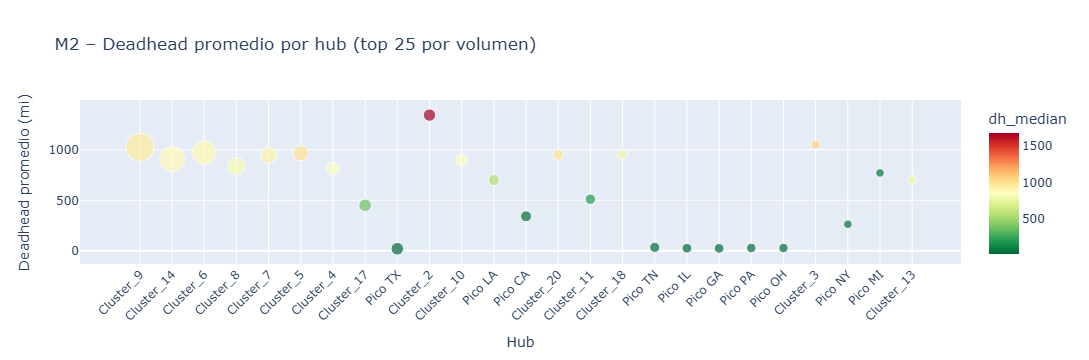

In [16]:
# Deadhead promedio por hub M2 (top 25 por volumen)
dh_hub = (
    df_dh.groupby('near_hub_name_m2')['deadhead_mi']
    .agg(['mean', 'median', 'count'])
    .reset_index()
    .rename(columns={'mean': 'dh_mean', 'median': 'dh_median',
                     'count': 'n_cargas', 'near_hub_name_m2': 'hub'})
    .sort_values('n_cargas', ascending=False)
    .head(25)
)

fig_dh_hub = px.scatter(
    dh_hub, x='hub', y='dh_mean',
    size='n_cargas', color='dh_median',
    color_continuous_scale='RdYlGn_r',
    title='M2 – Deadhead promedio por hub (top 25 por volumen)',
    labels={'dh_mean': 'Deadhead promedio (mi)', 'hub': 'Hub', 'n_cargas': 'N cargas'}
)
fig_dh_hub.update_layout(xaxis_tickangle=-45)
fig_dh_hub.show()

In [17]:
del df_dh
gc.collect()

1260

## 12. Conectividad entre hubs M2 (flujos origen → destino)

Pares de hubs M2 con flujo: 4,761


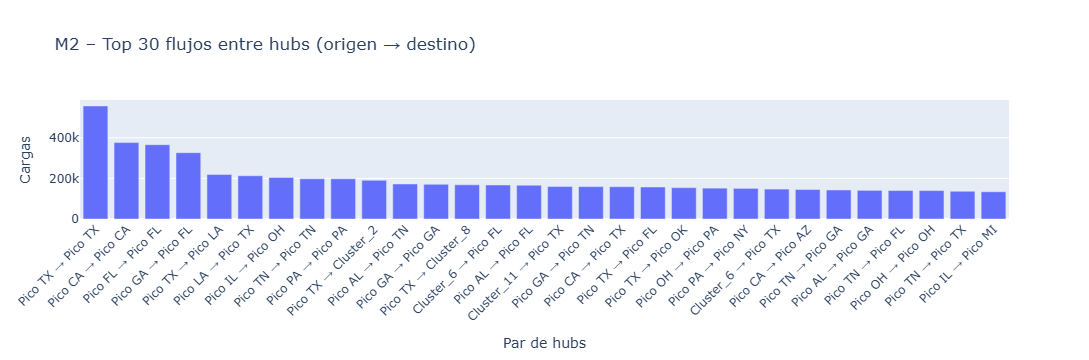

In [18]:
flujos = (
    df[df['near_hub_name_m2'].notna() & df['near_hub_name_dest_m2'].notna()]
    .groupby(['near_hub_name_m2', 'near_hub_name_dest_m2'])['ID']
    .count()
    .reset_index()
    .rename(columns={'ID': 'cargas',
                     'near_hub_name_m2': 'origen',
                     'near_hub_name_dest_m2': 'destino'})
    .sort_values('cargas', ascending=False)
)

print(f'Pares de hubs M2 con flujo: {len(flujos):,}')

top_flujos = flujos.head(30).copy()
top_flujos['par'] = top_flujos['origen'] + ' → ' + top_flujos['destino']

fig_flujo = px.bar(
    top_flujos, x='par', y='cargas',
    title='M2 – Top 30 flujos entre hubs (origen → destino)',
    labels={'cargas': 'Cargas', 'par': 'Par de hubs'}
)
fig_flujo.update_layout(xaxis_tickangle=-45)
fig_flujo.show()

In [20]:
hub_latlng_m2 = (
    hubs_table.drop_duplicates(subset=['hub_name'])
    .set_index('hub_name')[['lat', 'lng']]
    .to_dict('index')
)

m_conn = folium.Map(
    location=[38.5, -96], zoom_start=4,
    tiles='https://tiles.stadiamaps.com/tiles/alidade_smooth_dark/{z}/{x}/{y}{r}.png',
    attr='© Stadia Maps © OpenMapTiles © OpenStreetMap contributors'
)
max_fl = flujos['cargas'].iloc[0] if len(flujos) > 0 else 1

for _, row in flujos.head(50).iterrows():
    o, d = hub_latlng_m2.get(row['origen']), hub_latlng_m2.get(row['destino'])
    if o and d:
        weight = max(1, int(5 * row['cargas'] / max_fl))
        folium.PolyLine(
            [[o['lat'], o['lng']], [d['lat'], d['lng']]],
            weight=weight, color='#ff6b35', opacity=0.6,
            tooltip=f"{row['origen']} → {row['destino']}: {row['cargas']:,}"
        ).add_to(m_conn)

tier_colors = {'primaria': 'red', 'secundaria': 'orange', 'terciario': '#4499ff'}
for _, row in hubs_table.iterrows():
    folium.CircleMarker(
        [row['lat'], row['lng']], radius=4,
        color=tier_colors.get(row['tier'], 'gray'),
        fill=True, fill_opacity=0.8,
        popup=f"{row['hub_name']} [{row['tier']}]"
    ).add_to(m_conn)

m_conn.save('map_m2_conectividad.html')
print('✓ Mapa guardado: map_m2_conectividad.html')

✓ Mapa guardado: map_m2_conectividad.html


## 13. Distancia promedio de cargas por hub M2

Distancia promedio global de cargas M2: 728 millas
Distancia mediana global M2:            567 millas


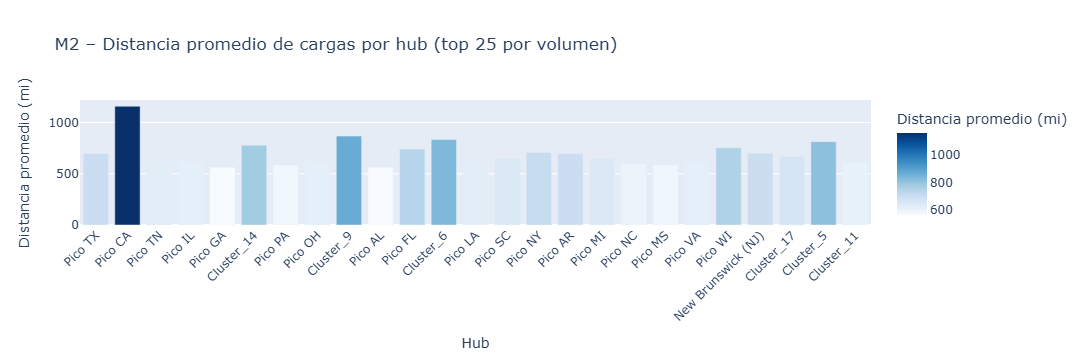

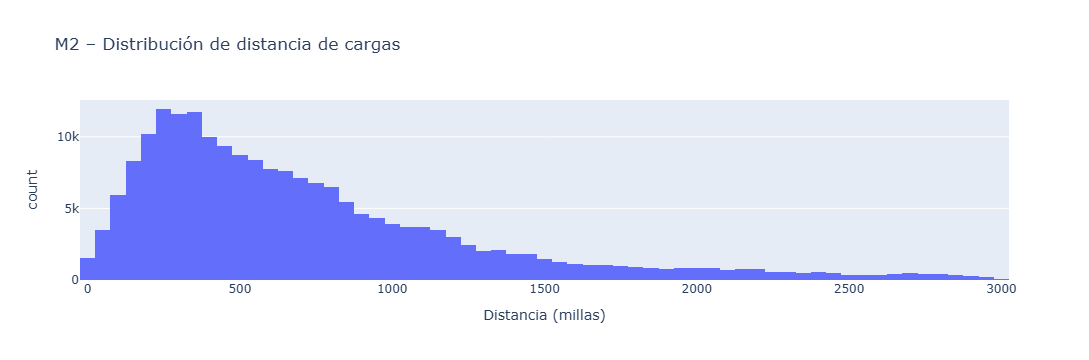

In [21]:
if 'Distance' in df.columns:
    dist_hub = (
        df[df['near_hub_name_m2'].notna()]
        .groupby('near_hub_name_m2')['Distance']
        .agg(['mean', 'median', 'count'])
        .reset_index()
        .rename(columns={'mean': 'dist_mean', 'median': 'dist_median',
                         'count': 'n_cargas', 'near_hub_name_m2': 'hub'})
        .sort_values('n_cargas', ascending=False)
    )

    print(f'Distancia promedio global de cargas M2: {df["Distance"].mean():.0f} millas')
    print(f'Distancia mediana global M2:            {df["Distance"].median():.0f} millas')

    fig_dist = px.bar(
        dist_hub.head(25),
        x='hub', y='dist_mean',
        color='dist_mean', color_continuous_scale='Blues',
        title='M2 – Distancia promedio de cargas por hub (top 25 por volumen)',
        labels={'dist_mean': 'Distancia promedio (mi)', 'hub': 'Hub'}
    )
    fig_dist.update_layout(xaxis_tickangle=-45)
    fig_dist.show()

    sample_dist = df[df['Distance'] < 3000]['Distance'].dropna()
    if len(sample_dist) > 200_000:
        sample_dist = sample_dist.sample(200_000, random_state=42)
    fig_dist_hist = px.histogram(
        sample_dist, x='Distance', nbins=80,
        title='M2 – Distribución de distancia de cargas',
        labels={'Distance': 'Distancia (millas)', 'count': 'N cargas'}
    )
    fig_dist_hist.show()

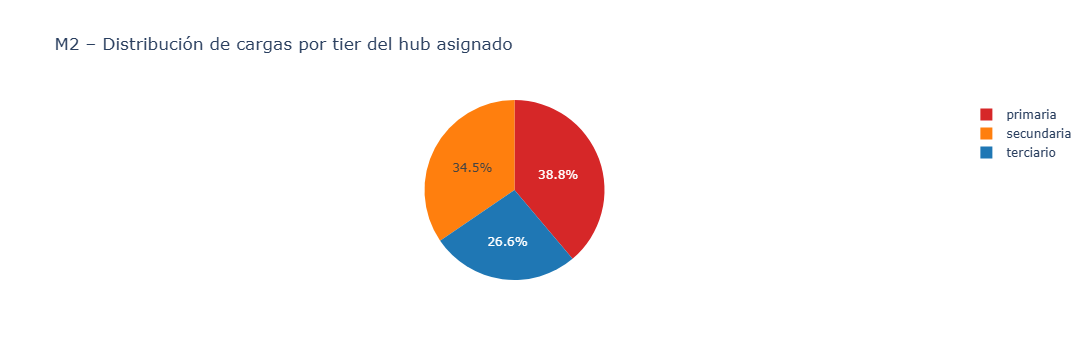

In [22]:
if 'tier_hub_m2' in df.columns:
    tier_counts = df['tier_hub_m2'].value_counts().reset_index()
    tier_counts.columns = ['tier', 'cargas']
    fig_tier = px.pie(
        tier_counts, names='tier', values='cargas',
        title='M2 – Distribución de cargas por tier del hub asignado',
        color='tier',
        color_discrete_map={'primaria': '#d62728', 'secundaria': '#ff7f0e', 'terciario': '#1f77b4'}
    )
    fig_tier.show()